# Simulating Currency Risk in Overseas Tuition Payments for Sri Lankan Families: A Monte Carlo Study

**Summary.** Sri Lankan families save for UK tuition in rupees but pay in pounds, so a weaker rupee between planning
and payment leaves them short. This notebook models the GBP/LKR exchange rate (Central Bank of Sri Lanka daily
indicative rates) with geometric Brownian motion and with a two-state calm/crisis Markov regime-switching model,
simulates many possible future paths by Monte Carlo, and estimates the extra rupees a family must set aside today to be
95% confident of covering a GBP 20,000 payment due in 3, 6 or 12 months (Value at Risk), together with the average
shortfall in the worst 5% of cases (Expected Shortfall). Every estimate is reported with a confidence interval over
independent replications and checked against closed-form results; the models are then backtested against what
actually happened, including the 2022 float of the rupee.

*Run with **Runtime → Run all** (about 2–3 minutes on a free Colab runtime). All random seeds are fixed (master seed
`SEED = 20261113`); the CBSL data file is included in the repository. AI assistance is disclosed in `AI_USAGE_LOG.md`.*

## 2. Problem and question

Studying abroad is common for Sri Lankan students, and the UK is a leading destination. Families usually save in
rupees (LKR) and pay fees in pounds (GBP) months later. If the rupee weakens in between, the rupee cost of the payment
rises: in March–April 2022, after the Central Bank allowed the rate to float, GBP/LKR rose by about 65% in six weeks.
An under-budgeted family may be forced into expensive borrowing, or the student's studies may be interrupted.

**Question.** *How many additional rupees must a family set aside today to be 95% confident of covering a GBP 20,000
tuition payment due in 3, 6 or 12 months?*

**Scope.** One payment of a fixed GBP amount; the family budgets at today's CBSL indicative rate $S_0$ and holds the
reserve in rupees (interest, bank spreads and hedging instruments are outside the core model and discussed in
Section 7). The answer is reported for GBP 20,000 but scales linearly with the amount.

## 3. Model, assumptions and equations

**Exchange-rate model 1: geometric Brownian motion (GBM).** With $S_t$ in LKR per GBP and $t$ in years,
$$dS_t=\mu S_t\,dt+\sigma S_t\,dW_t,\qquad S_T=S_0\exp\!\Big(\big(\mu-\tfrac12\sigma^2\big)T+\sigma W_T\Big),\quad W_T\sim N(0,T).$$
$\mu$ (per year) is the drift and $\sigma$ (per year$^{1/2}$) the volatility. Daily log-returns
$r_t=\ln(S_t/S_{t-1})$ are then i.i.d. $N\big((\mu-\tfrac12\sigma^2)\Delta t,\ \sigma^2\Delta t\big)$ with
$\Delta t = 1/241$ year (CBSL publishes about 241 rates a year).

**Exchange-rate model 2 (stretch goal): two-state Markov regime switching.** A hidden discrete-time Markov chain
$s_t\in\{0=\text{calm},1=\text{crisis}\}$ with transition matrix $P=\begin{pmatrix}p_{00}&1-p_{00}\\1-p_{11}&p_{11}\end{pmatrix}$
and $r_t\mid s_t=k\sim N(\mu_k,\sigma_k^2)$, calibrated by maximum likelihood with the Hamilton filter.

**Quantity of interest.** The family's shortfall in rupees and the two risk measures:
$$L=A\,(S_T-S_0),\qquad \mathrm{VaR}_\alpha=\inf\{\ell: P(L\le \ell)\ge\alpha\},\qquad \mathrm{ES}_\alpha=E[L\mid L\ge \mathrm{VaR}_\alpha],$$
with $A=20{,}000$ GBP and $\alpha=0.95$. $\mathrm{VaR}_{0.95}$ is the reserve; $\mathrm{ES}_{0.95}$ the average shortfall when the reserve is exceeded.

**Monte Carlo estimator.** With $N$ simulated values $L_i$, $\widehat{\mathrm{VaR}}$ is the empirical $\alpha$-quantile and
$\widehat{\mathrm{ES}}$ the mean of $L_i\ge\widehat{\mathrm{VaR}}$. $R$ independent replications give
$\bar x\pm t_{0.975,R-1}\,s_R/\sqrt R$; by the law of large numbers and the CLT the error falls like $N^{-1/2}$.

**Time-stepping.** Euler–Maruyama, $S_{n+1}=S_n(1+\mu\Delta t+\sigma\Delta W_n)$, has strong order $\tfrac12$ and weak order 1;
Milstein adds $\tfrac12\sigma^2S_n(\Delta W_n^2-\Delta t)$ for strong order 1.

**Assumptions.** (i) log-returns are normal and independent with constant parameters (GBM) or regime-dependent
parameters (switching model); (ii) parameters estimated from history describe the next 3–12 months; (iii) the CBSL
indicative rate is the rate the family pays; (iv) no interest on the reserve and no hedging.

| Concept applied | Where it is used |
|---|---|
| Monte Carlo integration and the law of large numbers | VaR/ES estimation, replication confidence intervals, $N^{-1/2}$ error check (Sections 4–6) |
| Input modelling and random variate generation | log-return analysis, Normal vs Student-t fits, MLE calibration, Box–Muller normals, inverse-transform regime switching (Section 4) |
| Discrete-time Markov chains | calm/crisis regime model, stationary distribution, Hamilton filter (Sections 4–5) |
| Numerical solvers and error orders | Euler–Maruyama and Milstein schemes, measured strong and weak convergence orders (Section 5) |

## 4. Implementation

The model code lives in the `fxrisk` package (`src/fxrisk/`); this section loads the data, checks the model inputs and calibrates both models.

### 4.1 Set-up

In [1]:
# Colab set-up: install packages and fetch the project code (skipped automatically when run inside the repository)
import os, subprocess, sys
REPO_URL = "https://github.com/DinethminMU/fx-tuition-risk.git"   # <-- replace with your public repository URL
if not any(os.path.isdir(os.path.join(p, "src", "fxrisk")) for p in (".", "..")):
    if not os.path.isdir("fx-tuition-risk"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    os.chdir("fx-tuition-risk/notebooks")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "numpy", "scipy", "pandas", "matplotlib", "statsmodels", "requests"], check=True)
print("working directory:", os.getcwd())

working directory: /home/claude/fx-tuition-risk/notebooks


In [2]:
import sys, time, warnings
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "fxrisk").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from inside the fx-tuition-risk repository.")
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from scipy import stats

from fxrisk import data, gbm, risk, rvgen, regime, backtest

# ---------------- experiment configuration ----------------
AMOUNT_GBP     = 20_000         # tuition payment (see Section 1 for justification)
ALPHA          = 0.95           # confidence level
HORIZON_MONTHS = [3, 6, 12]
N_PATHS        = 100_000        # paths per replication (GBM)
N_PATHS_MS     = 40_000         # paths per replication (regime-switching; loops over days)
N_REPS         = 30             # independent replications for confidence intervals
SEED           = 20261113
DATA_START     = "2011-01-01"
CSV_PATH       = ROOT / "data" / "cbsl_gbp_lkr.csv"
FIG_DIR        = ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)

# ---------------- plotting style ----------------
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": INK2, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelsize": 9.5, "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.5, "legend.frameon": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 1.6, "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]),
})
lkr_fmt = FuncFormatter(lambda x, _: f"{x:,.0f}")

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

def fmt(x):            # rupee formatting for tables
    return f"{x:,.0f}"

print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


### 4.2 Data: CBSL GBP/LKR indicative rates

**Source.** The CBSL publishes daily *indicative* exchange rates (LKR per unit of foreign currency) at
<https://www.cbsl.gov.lk/rates-and-indicators/exchange-rates>. The open-source Frankfurter API re-serves the same CBSL
series in machine-readable form (<https://frankfurter.dev/providers/cbsl/>); `data.get_rates` downloads it one year at a
time and caches it to `data/cbsl_gbp_lkr.csv`, so the analysis is reproducible offline.

**Data cleaning.** Before mid-2013 the series has gaps of up to two months (e.g. no observations between
4 April and 8 June 2012). A "daily" return across such a gap is really a multi-week return, and including it would
inflate the volatility estimate and create spurious outliers. The model is therefore calibrated on the segment after the
last gap longer than 14 calendar days, where observations are regular (about 240 per year).

**Tuition amount.** GBP 20,000 is a representative annual international undergraduate fee. For example, Bournemouth
University lists 2026/27 international undergraduate fees of GBP 19,635–24,150 a year
(<https://www.bournemouth.ac.uk/node/33346>), and Russell Group fees are higher still. All rupee risk figures scale
linearly with the amount, so results for other fees are a simple rescaling.

In [3]:
raw_rates, SOURCE = data.get_rates(CSV_PATH, start=DATA_START)
SYNTHETIC = SOURCE.startswith("SYNTHETIC")

# Data cleaning: calibrate only on the segment with regular daily observations
gaps = data.find_gaps(raw_rates, max_gap_days=14)
rates = data.regular_segment(raw_rates, max_gap_days=14)
print(f"Raw series: {len(raw_rates):,} obs from {raw_rates.index[0]:%Y-%m-%d}; "
      f"{len(gaps)} gaps longer than 14 days (longest {gaps.max() if len(gaps) else 0} days)")
if len(gaps):
    print("Gaps (calendar days, dated by the observation after the gap):", gaps.to_dict())
print(f"Using the regular segment from {rates.index[0]:%Y-%m-%d}: {len(rates):,} observations\n")
PPY = data.observations_per_year(rates)          # CBSL business days per year
S0 = float(rates.iloc[-1]); PLAN_DATE = rates.index[-1]
BUDGET = AMOUNT_GBP * S0
H_OBS = {m: int(round(m / 12 * PPY)) for m in HORIZON_MONTHS}

print(f"Source            : {SOURCE}")
print(f"Observations      : {len(rates):,}  ({rates.index[0]:%Y-%m-%d} to {PLAN_DATE:%Y-%m-%d})")
print(f"Obs per year      : {PPY:.0f}  ->  horizons in observations {H_OBS}")
print(f"Planning date S0  : {S0:,.4f} LKR/GBP")
print(f"Budget at S0      : LKR {BUDGET:,.0f} for GBP {AMOUNT_GBP:,}")
display(raw_rates.groupby(raw_rates.index.year).size().rename("observations per year").to_frame().T)
rates.describe().to_frame().T

Loaded 3507 CBSL observations from /home/claude/fx-tuition-risk/data/cbsl_gbp_lkr.csv
Raw series: 3,507 obs from 2011-01-20; 11 gaps longer than 14 days (longest 65 days)
Gaps (calendar days, dated by the observation after the gap): {Timestamp('2011-11-09 00:00:00'): 19, Timestamp('2012-01-02 00:00:00'): 17, Timestamp('2012-04-04 00:00:00'): 33, Timestamp('2012-06-08 00:00:00'): 65, Timestamp('2012-09-06 00:00:00'): 58, Timestamp('2013-01-01 00:00:00'): 42, Timestamp('2013-03-08 00:00:00'): 35, Timestamp('2013-04-05 00:00:00'): 28, Timestamp('2013-05-06 00:00:00'): 31, Timestamp('2013-06-06 00:00:00'): 17, Timestamp('2013-07-29 00:00:00'): 25}
Using the regular segment from 2013-07-29: 3,216 observations

Source            : CBSL via local file cbsl_gbp_lkr.csv
Observations      : 3,216  (2013-07-29 to 2026-11-20)
Obs per year      : 241  ->  horizons in observations {3: 60, 6: 120, 12: 241}
Planning date S0  : 435.5638 LKR/GBP
Budget at S0      : LKR 8,711,276 for GBP 20,000


date,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
observations per year,162,102,132,242,240,241,241,240,243,241,241,240,242,242,239,219


,count,mean,std,min,25%,50%,75%,max
GBP/LKR,3216.0,288.311425,92.791973,178.6569,211.111275,235.96785,394.375675,456.4336


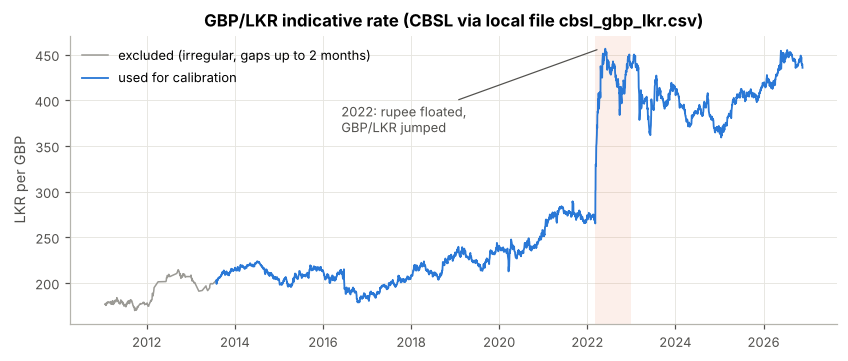

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.4))
early = raw_rates.loc[: rates.index[0]]
if len(early) > 1:
    ax.plot(early.index, early.values, color="#9b9a95", lw=1.0, label="excluded (irregular, gaps up to 2 months)")
ax.plot(rates.index, rates.values, color=BLUE, lw=1.2, label="used for calibration")
ax.legend(loc="upper left")
ax.axvspan(pd.Timestamp("2022-03-07"), pd.Timestamp("2022-12-31"), color=ORANGE, alpha=0.10, lw=0)
ax.annotate("2022: rupee floated,\nGBP/LKR jumped", xy=(pd.Timestamp("2022-04-15"), rates.loc["2022"].max()),
            xytext=(pd.Timestamp("2016-06-01"), rates.max() * 0.80), fontsize=8.5, color=INK2,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax.set_title(f"GBP/LKR indicative rate ({SOURCE})")
ax.set_ylabel("LKR per GBP"); ax.yaxis.set_major_formatter(lkr_fmt)
savefig(fig, "01_rates"); plt.show()

### 4.3 Input modelling and random variate generation

GBM assumes daily log-returns $r_t=\ln(S_t/S_{t-1})$ are **independent and normally distributed** with constant mean and
variance. Before relying on that assumption we check it:

* compare a fitted **Normal** with a fitted **Student-t** (heavier tails) by log-likelihood, AIC and the Kolmogorov–Smirnov distance;
* look at skewness, excess kurtosis and the Jarque–Bera test;
* plot rolling volatility to see whether variance is really constant.

We also verify the **random variate generator** that drives every simulated path: our own Box–Muller transform must
produce standard normals (KS test).

In [5]:
r = data.log_returns(rates)
print("Normality diagnostics:", {k: round(v, 4) for k, v in rvgen.normality_summary(r.values).items()})
fits = rvgen.fit_candidates(r.values)
fits.style.format({"loglik": "{:,.1f}", "AIC": "{:,.1f}", "KS": "{:.4f}", "KS_p": "{:.2e}"})

Normality diagnostics: {'skewness': 1.9882, 'excess_kurtosis': 41.2199, 'jarque_bera': 229723.9175, 'jarque_bera_p': 0.0}


,params,k,loglik,AIC,KS,KS_p
distribution,,,,,,
Normal,"mu=2.38e-04, sd=7.49e-03",2,"11,172.1","-22,340.2",0.0900,4.03e-23
Student-t,"nu=2.18, loc=-1.48e-04, scale=4.03e-03",3,"11,784.1","-23,562.2",0.0348,8.15e-04


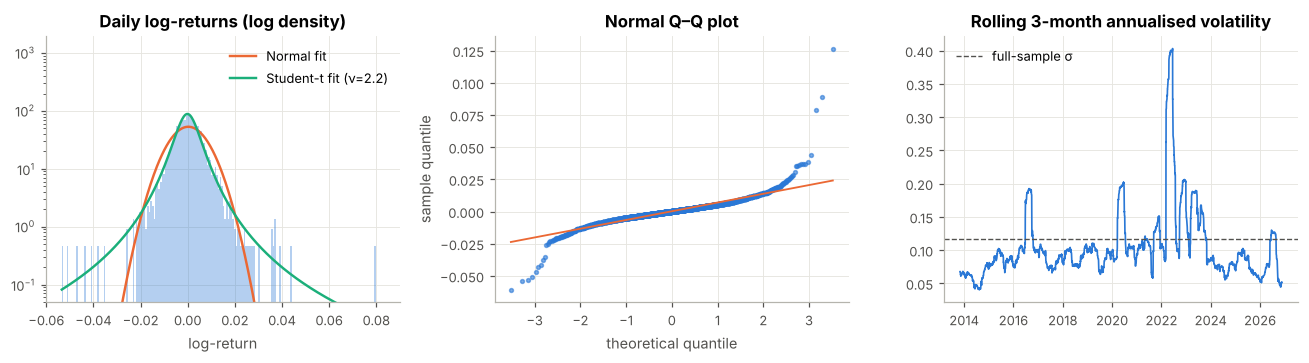

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
x = np.linspace(np.quantile(r, 0.0005), np.quantile(r, 0.9995), 400)
mu_n, sd_n = stats.norm.fit(r); nu, loc_t, sc_t = stats.t.fit(r)
ax = axes[0]
ax.hist(r, bins=200, range=(x[0], x[-1]), density=True, color=BLUE, alpha=0.35, lw=0)
ax.plot(x, stats.norm.pdf(x, mu_n, sd_n), color=ORANGE, label="Normal fit")
ax.plot(x, stats.t.pdf(x, nu, loc_t, sc_t), color=AQUA, label=f"Student-t fit (ν={nu:.1f})")
ax.set_yscale("log"); ax.set_ylim(bottom=0.05); ax.set_title("Daily log-returns (log density)")
ax.set_xlabel("log-return"); ax.legend()
ax = axes[1]
(osm, osr), (slope, intercept, _) = stats.probplot(r, dist="norm")
ax.plot(osm, osr, "o", ms=2.5, color=BLUE, alpha=0.6)
ax.plot(osm, slope * osm + intercept, color=ORANGE, lw=1.2)
ax.set_title("Normal Q–Q plot"); ax.set_xlabel("theoretical quantile"); ax.set_ylabel("sample quantile")
ax = axes[2]
roll = r.rolling(63).std() * np.sqrt(PPY)
ax.plot(roll.index, roll.values, color=BLUE, lw=1.1)
ax.axhline(r.std() * np.sqrt(PPY), color=INK2, lw=0.9, ls="--", label="full-sample σ")
ax.set_title("Rolling 3-month annualised volatility"); ax.legend()
fig.tight_layout(); savefig(fig, "02_input_modelling"); plt.show()

In [7]:
# Random variate generation check: Box–Muller normals vs N(0,1)
rng = np.random.default_rng(SEED)
z_bm = rvgen.box_muller(200_000, rng)
ks_bm = stats.kstest(z_bm, "norm")
print(f"Box–Muller: mean={z_bm.mean():+.4f}, sd={z_bm.std():.4f}, KS={ks_bm.statistic:.4f}, p={ks_bm.pvalue:.3f}")
assert ks_bm.pvalue > 0.001, "Box–Muller output is not standard normal"

Box–Muller: mean=-0.0025, sd=0.9995, KS=0.0019, p=0.474


**Interpretation.** Exchange-rate returns are typically **heavy-tailed** (large excess kurtosis; the Student-t beats the
Normal on AIC, and the Q–Q plot bends away from the line in both tails) and show **volatility clustering** (calm years
followed by bursts). Both features break GBM's assumptions. GBM is still the right *baseline*: it is the standard model,
it has closed-form answers we can verify against, and its failure modes are exactly what the regime-switching model in
Section 4.5 addresses.

### 4.4 GBM calibration

$$dS_t=\mu S_t\,dt+\sigma S_t\,dW_t \quad\Longrightarrow\quad S_T=S_0\exp\!\Big(\big(\mu-\tfrac12\sigma^2\big)T+\sigma W_T\Big).$$

Daily log-returns are then i.i.d. $N\big((\mu-\tfrac12\sigma^2)\Delta t,\ \sigma^2\Delta t\big)$ with $\Delta t = 1/\text{(obs per year)}$,
so the maximum-likelihood estimates come from the sample mean $m$ and standard deviation $s$:
$\hat\sigma = s/\sqrt{\Delta t}$ and $\hat\mu = m/\Delta t + \tfrac12\hat\sigma^2$.
Standard errors: $\operatorname{se}(\hat\mu)\approx\hat\sigma/\sqrt{\text{years of data}}$ and $\operatorname{se}(\hat\sigma)\approx\hat\sigma/\sqrt{2n}$.

The headline model is calibrated on the **full history**, which is the natural choice when GBM says the parameters are
constant. Section 6.4 shows how much the answer depends on this choice.

In [8]:
G = gbm.calibrate(rates.values, PPY)
print(G)
print(f"Drift t-statistic: {G.mu / G.se_mu:.2f}  (the drift is estimated far less precisely than the volatility)")

GBM(mu=0.0641 ± 0.0318/yr, sigma=0.1163 ± 0.0015/yr, n=3215)
Drift t-statistic: 2.01  (the drift is estimated far less precisely than the volatility)


### 4.5 Two-state Markov regime-switching model (stretch goal)

GBM gives the rupee one volatility forever. The data instead alternate between **calm** periods and **crisis** periods
(2015–16, 2018, 2020 and especially 2022). We model this with a hidden discrete-time Markov chain (DTMC)
$s_t\in\{0=\text{calm},1=\text{crisis}\}$:
$$P=\begin{pmatrix}p_{00}&1-p_{00}\\1-p_{11}&p_{11}\end{pmatrix},\qquad r_t\mid s_t=k\sim N(\mu_k,\sigma_k^2).$$

* **Calibration:** maximum likelihood via the **Hamilton filter** (forward recursion over regime probabilities);
  the **Kim smoother** gives $P(s_t=\text{crisis}\mid\text{all data})$. The filter is cross-checked against `statsmodels`.
* **DTMC facts:** stationary distribution $\pi=\pi P$, so $\pi_1=(1-p_{00})/(2-p_{00}-p_{11})$; expected time in regime $k$ is $1/(1-p_{kk})$.
* **Simulation:** start from the filtered regime probabilities on the planning date; each day, switch regime iff $U\ge p_{kk}$
  (inverse transform), then draw the day's return from that regime.

In [9]:
t0 = time.perf_counter()
MS = regime.fit(r.values, PPY)
print(f"fitted in {time.perf_counter()-t0:.1f}s\n" + MS.summary())

# Verification: transition matrix rows sum to 1 and pi is stationary
regime.validate_transition_matrix(MS.P)
pi = MS.stationary
assert np.allclose(pi @ MS.P, pi)
print("\nP =\n", np.round(MS.P, 5), "\nrow sums:", MS.P.sum(axis=1))

# Model comparison against i.i.d. normal returns (= GBM)
ll_gbm = stats.norm.logpdf(r, r.mean(), r.std()).sum()
print(f"\nlog-likelihood  GBM {ll_gbm:,.1f} (k=2, AIC {4 - 2*ll_gbm:,.1f})  |  regime {MS.loglik:,.1f} (k=6, AIC {12 - 2*MS.loglik:,.1f})")

try:
    import statsmodels.api as sm
    sm_res = sm.tsa.MarkovRegression(r.values, k_regimes=2, trend="c", switching_variance=True).fit(disp=False, search_reps=5)
    print(f"statsmodels cross-check: loglik {sm_res.llf:,.3f} vs ours {MS.loglik:,.3f}")
    assert abs(sm_res.llf - MS.loglik) < 1e-3 * abs(sm_res.llf) or MS.loglik > sm_res.llf
except ImportError:
    print("statsmodels not installed; cross-check skipped")

fitted in 0.5s
calm  : mu=+0.014/yr sigma=0.078/yr  p_stay=0.9832  E[duration]=59 obs  pi=0.912
crisis: mu=+0.511/yr sigma=0.299/yr  p_stay=0.8246  E[duration]=6 obs  pi=0.088
loglik=11871.5, n=3215, P(crisis | data to last date)=0.008

P =
 [[0.98315 0.01685]
 [0.17539 0.82461]] 
row sums: [1. 1.]

log-likelihood  GBM 11,172.1 (k=2, AIC -22,340.2)  |  regime 11,871.5 (k=6, AIC -23,731.0)


statsmodels cross-check: loglik 11,871.508 vs ours 11,871.508


### 4.6 Monte Carlo estimator of VaR and ES

The family budgets at today's rate $S_0$. The **shortfall** at payment time $T$ is
$$L = 20{,}000\,(S_T - S_0)\ \text{LKR}.$$

* **95% VaR** = the 95th percentile of $L$ = the **extra rupees to set aside today** for 95% confidence.
* **95% ES** = $E[L\mid L\ge \text{VaR}]$ = the average shortfall in the worst 5% of outcomes (how bad a "bad case" is).

Each estimate is the mean of **R = 30 independent replications** (separate `SeedSequence` streams) of
N = 100,000 paths each. The 95% confidence interval uses the Student-t distribution over replications:
$\bar x \pm t_{0.975,R-1}\, s_R/\sqrt R$. For GBM the exact solution is used (one normal draw per path); Euler–Maruyama
is examined in Section 5.

In [10]:
rows, gbm_mc = [], {}
for m in HORIZON_MONTHS:
    T = m / 12
    sampler = lambda rng, T=T: risk.shortfall(gbm.sample_terminal(S0, G.mu, G.sigma, T, N_PATHS, rng), S0, AMOUNT_GBP)
    t0 = time.perf_counter()
    out = risk.replicate(sampler, N_REPS, ALPHA, seed=SEED + m)
    secs = time.perf_counter() - t0
    var_a, es_a = risk.analytic_var_es(S0, G.mu, G.sigma, T, AMOUNT_GBP, ALPHA)
    gbm_mc[m] = dict(out=out, var_a=var_a, es_a=es_a)
    rows.append({
        "horizon": f"{m} months",
        "VaR (MC) [95% CI]": str(out["VaR"]), "VaR analytic": fmt(var_a),
        "VaR rel. error": f"{out['VaR'].mean / var_a - 1:+.3%}",
        "ES (MC) [95% CI]": str(out["ES"]), "ES analytic": fmt(es_a),
        "VaR % of budget": f"{out['VaR'].mean / BUDGET:.1%}",
        "total to hold (LKR)": fmt(BUDGET + out["VaR"].mean),
        "time (s)": f"{secs:.1f}",
    })
print(f"Budget at today's rate: LKR {BUDGET:,.0f}   |   {N_REPS} reps x {N_PATHS:,} paths")
mvp_table = pd.DataFrame(rows).set_index("horizon"); mvp_table

Budget at today's rate: LKR 8,711,276   |   30 reps x 100,000 paths


,VaR (MC) [95% CI],VaR analytic,VaR rel. error,ES (MC) [95% CI],ES analytic,VaR % of budget,total to hold (LKR),time (s)
horizon,,,,,,,,
3 months,"1,012,972 [1,011,352, 1,014,592]","1,013,032",-0.006%,"1,254,211 [1,252,351, 1,256,071]","1,254,613",11.6%,"9,724,248",0.1
6 months,"1,552,964 [1,550,818, 1,555,110]","1,552,271",+0.045%,"1,918,326 [1,915,857, 1,920,795]","1,916,201",17.8%,"10,264,240",0.1
12 months,"2,461,894 [2,459,260, 2,464,529]","2,459,767",+0.086%,"3,027,589 [3,023,574, 3,031,604]","3,027,367",28.3%,"11,173,170",0.1


## 5. Verification

Each check below is an `assert`, so the notebook fails loudly if the simulator is wrong.

**Tolerances.** A Monte Carlo estimate has random error, so we compare against the analytic value using its standard
error over replications, SE $= s_R/\sqrt R$. A check passes if the error is within **4 SE** (a correct simulator fails this
by chance with probability about 6 in 100,000) **and** the relative error is below **1%** (a practical accuracy requirement).

### 5.1 Monte Carlo VaR / ES vs the closed-form lognormal results
For GBM, $S_T$ is lognormal, so
$q_\alpha = S_0\exp\big((\mu-\tfrac12\sigma^2)T+\sigma\sqrt T\,z_\alpha\big)$ and
$E[S_T\mid S_T\ge q_\alpha] = S_0e^{\mu T}\,\Phi(\sigma\sqrt T - z_\alpha)/(1-\alpha)$.

In [11]:
checks = []
for m in HORIZON_MONTHS:
    d = gbm_mc[m]
    for meas, exact in (("VaR", d["var_a"]), ("ES", d["es_a"])):
        est = d["out"][meas]; se = est.sd / np.sqrt(est.n_reps)
        z = (est.mean - exact) / se; rel = est.mean / exact - 1
        checks.append(dict(horizon=m, measure=meas, mc=est.mean, analytic=exact, z_score=z, rel_error=rel))
        assert abs(z) < 4 and abs(rel) < 0.01, f"{meas} {m}m failed: z={z:.2f}, rel={rel:.3%}"
pd.DataFrame(checks).style.format({"mc": "{:,.0f}", "analytic": "{:,.0f}", "z_score": "{:+.2f}", "rel_error": "{:+.3%}"})

,horizon,measure,mc,analytic,z_score,rel_error
0,3,VaR,"1,012,972","1,013,032",-0.08,-0.006%
1,3,ES,"1,254,211","1,254,613",-0.44,-0.032%
2,6,VaR,"1,552,964","1,552,271",+0.66,+0.045%
3,6,ES,"1,918,326","1,916,201",+1.76,+0.111%
4,12,VaR,"2,461,894","2,459,767",+1.65,+0.086%
5,12,ES,"3,027,589","3,027,367",+0.11,+0.007%


### 5.2 Monte Carlo mean vs $E[S_T]=S_0e^{\mu T}$, and the law of large numbers
The running sample mean must settle on the analytic expectation (LLN) and the error must shrink like $1/\sqrt N$ (CLT).
We measure that rate empirically: the RMSE of the VaR estimator over 40 replications at each N should have log–log slope $-\tfrac12$.

MC mean 449.7857 vs analytic 449.7581  (diff +0.0276, SE 0.0370)


VaR estimator RMSE ~ N^-0.492   (theory: N^-0.5)


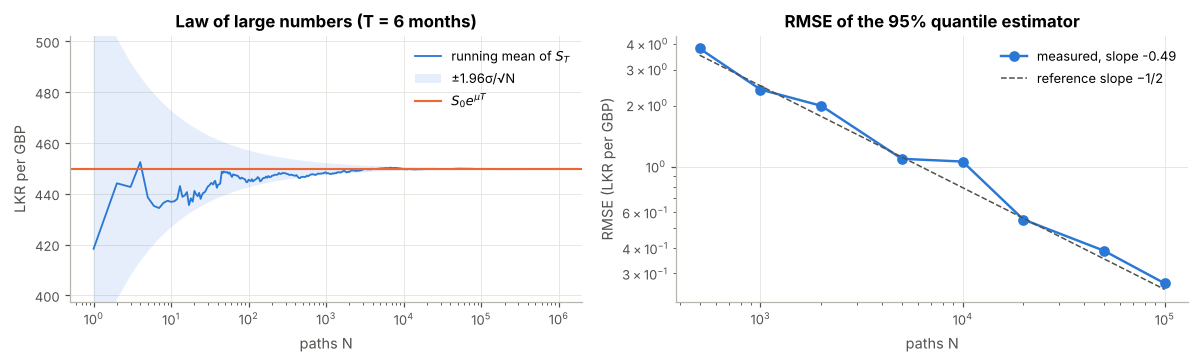

In [12]:
rng = np.random.default_rng(SEED + 1)
T = 0.5
sT = gbm.sample_terminal(S0, G.mu, G.sigma, T, 1_000_000, rng)
exact_mean = gbm.analytic_mean(S0, G.mu, T)
se_mean = sT.std(ddof=1) / np.sqrt(sT.size)
print(f"MC mean {sT.mean():.4f} vs analytic {exact_mean:.4f}  (diff {sT.mean()-exact_mean:+.4f}, SE {se_mean:.4f})")
assert abs(sT.mean() - exact_mean) < 4 * se_mean

running = np.cumsum(sT) / np.arange(1, sT.size + 1)

Ns = np.array([500, 1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000])
var_exact = gbm.analytic_quantile(S0, G.mu, G.sigma, T, ALPHA)
rmse = []
for N in Ns:
    est = [np.quantile(gbm.sample_terminal(S0, G.mu, G.sigma, T, N, rng), ALPHA) for _ in range(40)]
    rmse.append(np.sqrt(np.mean((np.array(est) - var_exact) ** 2)))
rmse = np.array(rmse)
slope, icpt = gbm.fit_order(Ns, rmse)
print(f"VaR estimator RMSE ~ N^{slope:.3f}   (theory: N^-0.5)")
assert -0.62 < slope < -0.38

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
n_idx = np.unique(np.geomspace(1, sT.size, 400).astype(int)) - 1
ax.plot(n_idx + 1, running[n_idx], color=BLUE, lw=1.2, label="running mean of $S_T$")
band = 1.96 * sT.std() / np.sqrt(n_idx + 1)
ax.fill_between(n_idx + 1, exact_mean - band, exact_mean + band, color=BLUE, alpha=0.12, lw=0, label="±1.96σ/√N")
ax.axhline(exact_mean, color=ORANGE, lw=1.4, label="$S_0e^{\\mu T}$")
ax.set_xscale("log"); ax.set_ylim(exact_mean - 4 * band[30], exact_mean + 4 * band[30])
ax.set_title("Law of large numbers (T = 6 months)"); ax.set_xlabel("paths N"); ax.set_ylabel("LKR per GBP"); ax.legend()
ax = axes[1]
ax.loglog(Ns, rmse, "o-", color=BLUE, ms=6, label=f"measured, slope {slope:.2f}")
ax.loglog(Ns, np.exp(icpt) * Ns ** -0.5, color=INK2, ls="--", lw=1, label="reference slope −1/2")
ax.set_title("RMSE of the 95% quantile estimator"); ax.set_xlabel("paths N"); ax.set_ylabel("RMSE (LKR per GBP)"); ax.legend()
fig.tight_layout(); savefig(fig, "04_lln_convergence"); plt.show()

### 5.3 Euler–Maruyama convergence (numerical time-stepping and error orders)
Euler–Maruyama is the stochastic analogue of the forward Euler ODE solver:
$$S_{n+1}=S_n\,(1+\mu\,\Delta t+\sigma\,\Delta W_n).$$
For ODEs, forward Euler has global order 1. With noise, the **strong** (pathwise) error
$E|S^{EM}_T-S_T|$ only falls like $\Delta t^{1/2}$, while the **weak** error $|E[S^{EM}_T]-E[S_T]|$ keeps order 1.
Milstein adds the Itô correction $\tfrac12\sigma^2S_n(\Delta W_n^2-\Delta t)$ and recovers strong order 1.

To measure strong error, every step size must use the **same Brownian path**: we simulate fine increments and sum
blocks of them for coarser grids. For the weak error of GBM, $E[S^{EM}_T]=S_0(1+\mu\Delta t)^{T/\Delta t}$ exactly, so it
has no Monte Carlo noise.

Measured orders:  EM strong 0.502 (theory 0.5) | Milstein strong 0.994 (theory 1) | EM weak 0.998 (theory 1)


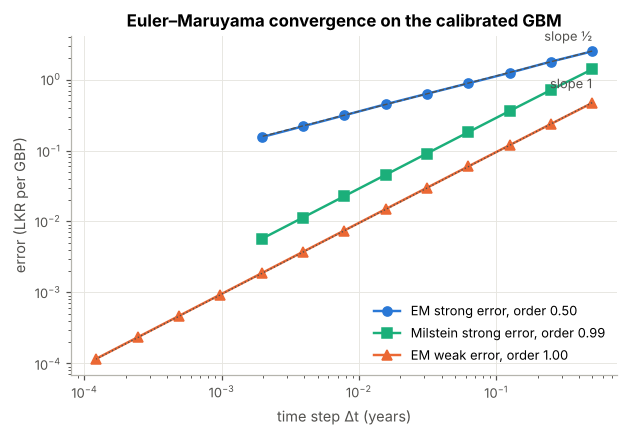

In [13]:
rng = np.random.default_rng(SEED + 2)
T, fine_exp = 1.0, 12
fine = 2 ** fine_exp
levels = np.arange(1, 10)                         # 2 .. 512 steps
dW = gbm.brownian_increments(T, fine, 4_000, rng)
exact_T = gbm.exact_terminal_from_increments(S0, G.mu, G.sigma, T, dW)
h, e_em, e_mil = [], [], []
for k in levels:
    dWk = gbm.coarsen(dW, fine // 2 ** k)
    h.append(T / 2 ** k)
    e_em.append(np.mean(np.abs(gbm.euler_maruyama(S0, G.mu, G.sigma, T, dWk) - exact_T)))
    e_mil.append(np.mean(np.abs(gbm.milstein(S0, G.mu, G.sigma, T, dWk) - exact_T)))
h, e_em, e_mil = map(np.array, (h, e_em, e_mil))
N_w = 2 ** np.arange(1, 14)
h_w = T / N_w
e_weak = np.abs(gbm.em_expected_terminal(S0, G.mu, T, N_w) - gbm.analytic_mean(S0, G.mu, T))

p_strong, c_s = gbm.fit_order(h, e_em)
p_mil, c_m = gbm.fit_order(h, e_mil)
p_weak, c_w = gbm.fit_order(h_w, e_weak)
print(f"Measured orders:  EM strong {p_strong:.3f} (theory 0.5) | Milstein strong {p_mil:.3f} (theory 1) | EM weak {p_weak:.3f} (theory 1)")
assert 0.4 < p_strong < 0.6 and 0.85 < p_mil < 1.15 and 0.95 < p_weak < 1.05

fig, ax = plt.subplots(figsize=(6.4, 4))
ax.loglog(h, e_em, "o-", color=BLUE, ms=6, label=f"EM strong error, order {p_strong:.2f}")
ax.loglog(h, e_mil, "s-", color=AQUA, ms=6, label=f"Milstein strong error, order {p_mil:.2f}")
ax.loglog(h_w, e_weak, "^-", color=ORANGE, ms=6, label=f"EM weak error, order {p_weak:.2f}")
ax.loglog(h, np.exp(c_s) * h ** 0.5, color=INK2, ls="--", lw=0.9)
ax.loglog(h_w, np.exp(c_w) * h_w ** 1.0, color=INK2, ls=":", lw=0.9)
ax.text(h[0], np.exp(c_s) * h[0] ** 0.5 * 1.4, "slope ½", fontsize=8.5, color=INK2, ha="right")
ax.text(h_w[0], np.exp(c_w) * h_w[0] * 1.6, "slope 1", fontsize=8.5, color=INK2, ha="right")
ax.set_xlabel("time step Δt (years)"); ax.set_ylabel("error (LKR per GBP)")
ax.set_title("Euler–Maruyama convergence on the calibrated GBM"); ax.legend(loc="lower right")
savefig(fig, "05_em_convergence"); plt.show()

In [14]:
# What does the discretisation error mean for the actual answer? 6-month VaR using common random numbers.
rng = np.random.default_rng(SEED + 3)
T, n_days = 0.5, 126                    # 126 = 2 x 3^2 x 7, so 1, 2, 6, 21 and 126 steps all divide it exactly
dW = gbm.brownian_increments(T, n_days, 100_000, rng)
L_exact = risk.shortfall(gbm.exact_terminal_from_increments(S0, G.mu, G.sigma, T, dW), S0, AMOUNT_GBP)
v_exact = risk.var_es(L_exact, ALPHA)[0]
rows = []
for steps in [1, 2, 6, 21, 126]:
    dWk = gbm.coarsen(dW, n_days // steps)
    L = risk.shortfall(gbm.euler_maruyama(S0, G.mu, G.sigma, T, dWk), S0, AMOUNT_GBP)
    v = risk.var_es(L, ALPHA)[0]
    rows.append({"EM steps": steps, "Δt (days)": n_days // steps, "VaR (EM)": fmt(v), "VaR (exact)": fmt(v_exact),
                 "difference": f"{v - v_exact:+,.0f}"})
pd.DataFrame(rows).set_index("EM steps")

,Δt (days),VaR (EM),VaR (exact),difference
EM steps,,,,
1,126,"1,452,625","1,546,004","-93,380"
2,63,"1,498,409","1,546,004","-47,595"
6,21,"1,530,961","1,546,004","-15,044"
21,6,"1,541,673","1,546,004","-4,331"
126,1,"1,544,934","1,546,004","-1,070"


With daily steps the Euler–Maruyama answer is practically identical to the exact one; even monthly steps give an error
far smaller than the Monte Carlo CI. For GBM the exact solution is still preferred: it is faster and has **no
discretisation bias**. Time-stepping matters for models without a closed-form solution, such as the regime-switching
model below, which is simulated day by day.

### 5.4 Markov-chain checks
Rows of the fitted transition matrix sum to 1 (asserted in 4.5), $\pi P=\pi$, and a long simulated chain visits each regime with the stationary frequencies. The plot shows when the fitted model believes the rupee was in crisis.

simulated frequencies [0.9128 0.0872]  vs  stationary [0.9124 0.0876]


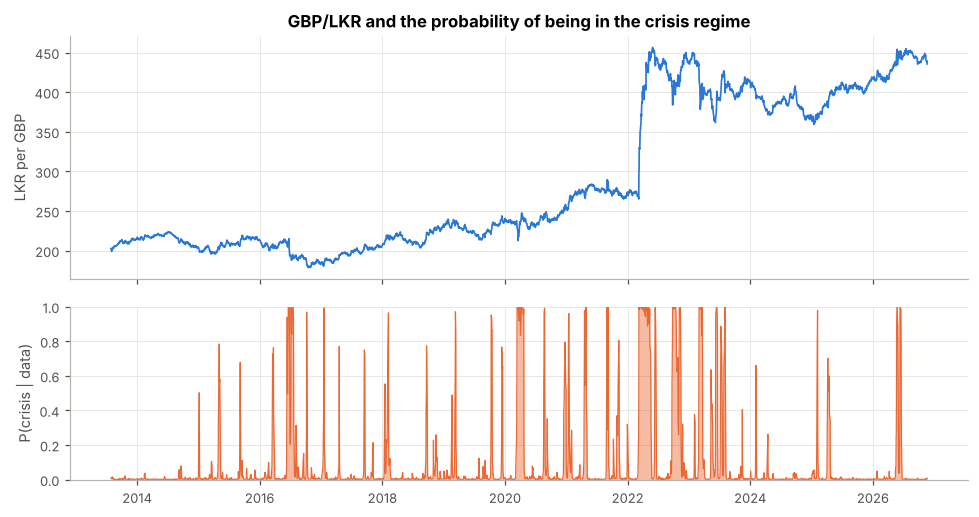

In [15]:
# Verification: simulated regime frequencies match the stationary distribution
rng = np.random.default_rng(SEED + 4)
chain = regime.simulate_chain(MS.P, 2_000_000, rng)
freq = np.bincount(chain, minlength=2) / chain.size
print(f"simulated frequencies {np.round(freq, 4)}  vs  stationary {np.round(pi, 4)}")
assert np.allclose(freq, pi, atol=0.01)

filt, smooth = regime.smoothed_probabilities(r.values, MS)
fig, axes = plt.subplots(2, 1, figsize=(9, 4.8), sharex=True, gridspec_kw=dict(height_ratios=[1.4, 1]))
axes[0].plot(rates.index, rates.values, color=BLUE, lw=1.1)
axes[0].set_ylabel("LKR per GBP"); axes[0].yaxis.set_major_formatter(lkr_fmt)
axes[0].set_title("GBP/LKR and the probability of being in the crisis regime")
axes[1].fill_between(r.index, smooth[:, 1], color=ORANGE, alpha=0.45, lw=0)
axes[1].plot(r.index, smooth[:, 1], color=ORANGE, lw=0.8)
axes[1].set_ylim(0, 1); axes[1].set_ylabel("P(crisis | data)")
fig.tight_layout(); savefig(fig, "06_regimes"); plt.show()

## 6. Experiments and results

### 6.1 The reserve under GBM
The table in 4.6 gives the GBM reserve for each horizon. The fan chart shows the simulated paths and the shortfall distribution.

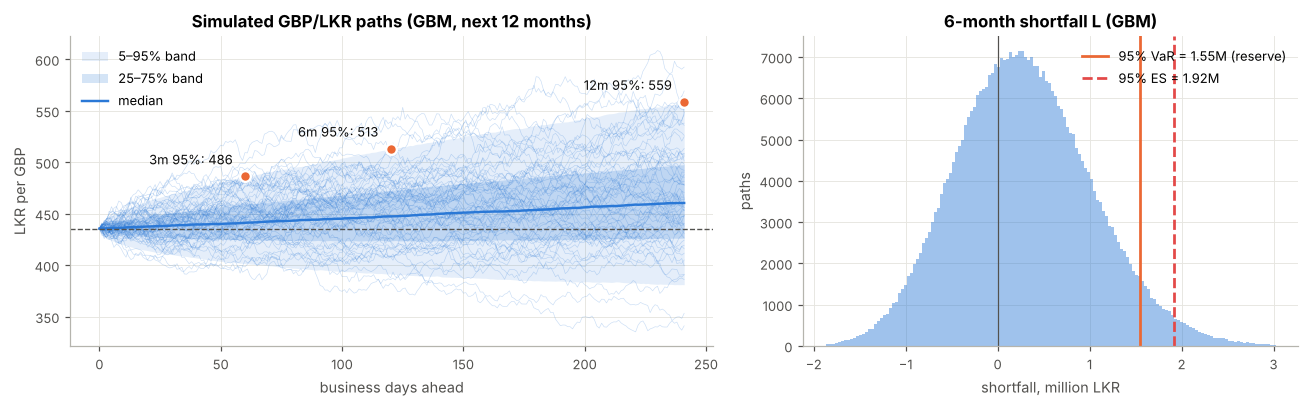

In [16]:
# Fan chart of simulated paths + distribution of the 6-month shortfall
rng = np.random.default_rng(SEED)
n_days = H_OBS[12]
dW = gbm.brownian_increments(1.0, n_days, 20_000, rng)
paths = gbm.exact_paths(S0, G.mu, G.sigma, 1.0, dW)
days = np.arange(n_days + 1)
qs = np.quantile(paths, [0.05, 0.25, 0.5, 0.75, 0.95], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
ax = axes[0]
for i in range(60):
    ax.plot(days, paths[i], color=BLUE, lw=0.4, alpha=0.25)
ax.fill_between(days, qs[0], qs[4], color=BLUE, alpha=0.12, lw=0, label="5–95% band")
ax.fill_between(days, qs[1], qs[3], color=BLUE, alpha=0.20, lw=0, label="25–75% band")
ax.plot(days, qs[2], color=BLUE, lw=1.6, label="median")
for m in HORIZON_MONTHS:
    q = gbm.analytic_quantile(S0, G.mu, G.sigma, m / 12, ALPHA)
    ax.plot(H_OBS[m], q, "o", ms=7, color=ORANGE, mec="white", mew=1.5, zorder=5)
    ax.annotate(f"{m}m 95%: {q:,.0f}", (H_OBS[m], q), xytext=(-8, 8), textcoords="offset points",
                ha="right", fontsize=8.5, color=INK)
ax.axhline(S0, color=INK2, lw=0.9, ls="--")
ax.set_title("Simulated GBP/LKR paths (GBM, next 12 months)"); ax.set_xlabel("business days ahead")
ax.set_ylabel("LKR per GBP"); ax.yaxis.set_major_formatter(lkr_fmt); ax.legend(loc="upper left")

ax = axes[1]
L6 = risk.shortfall(gbm.sample_terminal(S0, G.mu, G.sigma, 0.5, 400_000, rng), S0, AMOUNT_GBP)
v6, e6 = risk.var_es(L6, ALPHA)
lo, hi = np.quantile(L6, [0.0005, 0.9995]) / 1e6
ax.hist(L6 / 1e6, bins=150, range=(lo, hi), color=BLUE, alpha=0.45, lw=0)
ax.axvline(v6 / 1e6, color=ORANGE, lw=1.8, label=f"95% VaR = {v6/1e6:.2f}M (reserve)")
ax.axvline(e6 / 1e6, color=RED, lw=1.8, ls="--", label=f"95% ES = {e6/1e6:.2f}M")
ax.axvline(0, color=INK2, lw=0.8)
ax.legend(loc="upper right")
ax.set_title("6-month shortfall L (GBM)"); ax.set_xlabel("shortfall, million LKR"); ax.set_ylabel("paths")
fig.tight_layout(); savefig(fig, "03_gbm_paths_shortfall"); plt.show()

### 6.2 GBM vs regime switching
The same replication design applied to the switching model, and the effect of the regime on the planning date.

In [17]:
# Regime-switching VaR / ES with replications, compared with GBM
ms_mc, rows = {}, []
for m in HORIZON_MONTHS:
    h_obs = H_OBS[m]
    sampler = lambda rng, h_obs=h_obs: risk.shortfall(
        regime.simulate_terminal(S0, MS, h_obs, N_PATHS_MS, rng), S0, AMOUNT_GBP)
    out = risk.replicate(sampler, N_REPS, ALPHA, seed=SEED + 100 + m)
    ms_mc[m] = out
    g = gbm_mc[m]["out"]
    rows.append({"horizon": f"{m} months",
                 "GBM VaR": str(g["VaR"]), "Regime VaR": str(out["VaR"]),
                 "GBM ES": str(g["ES"]), "Regime ES": str(out["ES"]),
                 "Regime / GBM (VaR)": f"{out['VaR'].mean / g['VaR'].mean:.2f}x"})
print(f"P(crisis) on planning date {PLAN_DATE:%Y-%m-%d}: {MS.filtered_last[1]:.3f}")
cmp_table = pd.DataFrame(rows).set_index("horizon"); cmp_table

P(crisis) on planning date 2026-11-20: 0.008


,GBM VaR,Regime VaR,GBM ES,Regime ES,Regime / GBM (VaR)
horizon,,,,,
3 months,"1,012,972 [1,011,352, 1,014,592]","1,046,446 [1,043,663, 1,049,229]","1,254,211 [1,252,351, 1,256,071]","1,453,497 [1,448,604, 1,458,390]",1.03x
6 months,"1,552,964 [1,550,818, 1,555,110]","1,624,835 [1,621,356, 1,628,314]","1,918,326 [1,915,857, 1,920,795]","2,159,670 [2,153,502, 2,165,838]",1.05x
12 months,"2,461,894 [2,459,260, 2,464,529]","2,562,265 [2,555,853, 2,568,677]","3,027,589 [3,023,574, 3,031,604]","3,318,731 [3,310,635, 3,326,826]",1.04x


In [18]:
# How much does today's regime matter? 6-month VaR if the family plans in calm vs crisis conditions
rng = np.random.default_rng(SEED + 5)
rows = []
for label, p0 in [("calm today", [1.0, 0.0]), ("as filtered today", MS.filtered_last), ("crisis today", [0.0, 1.0])]:
    row = {"starting regime": label}
    for m in HORIZON_MONTHS:
        L = risk.shortfall(regime.simulate_terminal(S0, MS, H_OBS[m], 200_000, rng, init_probs=np.array(p0)), S0, AMOUNT_GBP)
        row[f"VaR {m}m"] = fmt(risk.var_es(L, ALPHA)[0])
    rows.append(row)
pd.DataFrame(rows).set_index("starting regime")

,VaR 3m,VaR 6m,VaR 12m
starting regime,,,
calm today,"1,047,256","1,616,703","2,553,662"
as filtered today,"1,049,148","1,625,493","2,575,551"
crisis today,"1,336,430","1,864,423","2,775,588"


### 6.3 Backtest against realised CBSL rates: would the model have protected a family in 2022?

On the first business day of every month from 2014 onwards we pretend to be a family planning a payment $h$ months
ahead. Each rule is calibrated **only on data available on that date**, sets a reserve, and is then compared with the
rate that actually occurred on the payment date. A *breach* means the family ran short.

Rules compared:
* **No reserve:** budget at today's rate (what many families do).
* **GBM (all history):** the headline GBM model on an expanding window.
* **GBM (last year):** GBM calibrated on the most recent 12 months only (reacts faster to new volatility).
* **Regime-switching:** the stretch model on an expanding window, refitted every month (warm-started).

A correct 95% rule should breach about 5% of the time; the **Kupiec proportion-of-failures test** checks this.
Payment windows overlap (e.g. 12-month plans made in consecutive months), so breaches are positively correlated and
Kupiec p-values are indicative only.

In [19]:
plan_pos = backtest.month_start_positions(rates.index, "2014-01-01", str(rates.index[-1].date()))
rules = {
    "No reserve": backtest.zero_reserve_fn(),
    "GBM (all history)": backtest.gbm_reserve_fn(PPY, ALPHA),
    "GBM (last year)": backtest.trailing(backtest.gbm_reserve_fn(PPY, ALPHA), int(PPY)),
    "Regime-switching": backtest.regime_reserve_fn(PPY, ALPHA, n_paths=20_000, seed=SEED),
}
names = list(rules)
t0 = time.perf_counter()
BT = {m: backtest.run(rates, plan_pos, H_OBS[m], None, rules, amount=AMOUNT_GBP, min_obs=int(2 * PPY))
      for m in HORIZON_MONTHS}
print(f"backtest finished in {time.perf_counter()-t0:.0f}s; plans per horizon: {[len(b) for b in BT.values()]}")

summ = pd.concat({f"{m}m": backtest.summarise(BT[m], names, ALPHA) for m in HORIZON_MONTHS})
summ.style.format({"breach_rate": "{:.1%}", "kupiec_p": "{:.3f}", "mean_reserve": "{:,.0f}",
                   "mean_uncovered": "{:,.0f}", "worst_uncovered": "{:,.0f}"})

backtest finished in 49s; plans per horizon: [133, 131, 124]


In [20]:
# Focus on payments that fell due in 2022
rows = []
for m in HORIZON_MONTHS:
    b = BT[m][BT[m]["pay_date"].dt.year == 2022]
    for nm in names:
        rows.append({"horizon": f"{m}m", "rule": nm, "plans": len(b),
                     "breaches": int(b[f"breach_{nm}"].sum()),
                     "mean reserve": b[f"reserve_{nm}"].mean(),
                     "mean shortfall not covered": b[f"uncovered_{nm}"].mean(),
                     "worst shortfall not covered": b[f"uncovered_{nm}"].max()})
y2022 = pd.DataFrame(rows).set_index(["horizon", "rule"])
y2022.style.format({"mean reserve": "{:,.0f}", "mean shortfall not covered": "{:,.0f}",
                    "worst shortfall not covered": "{:,.0f}"})

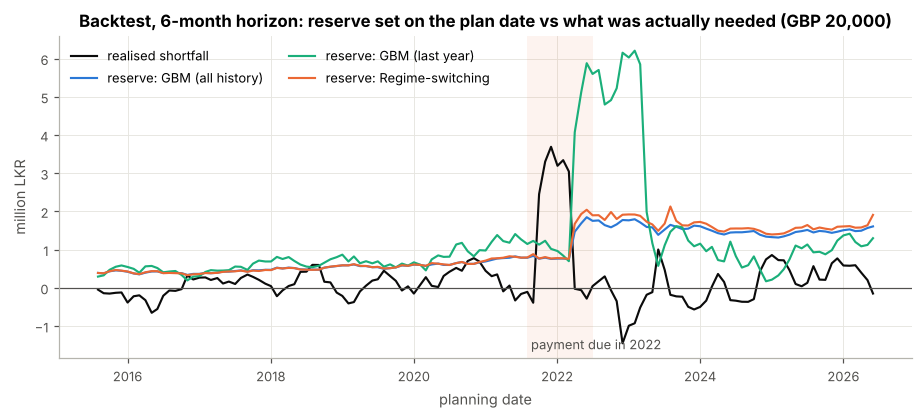

In [21]:
m = 6
b = BT[m]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axvspan(b.index[b["pay_date"].dt.year == 2022].min(), b.index[b["pay_date"].dt.year == 2022].max(),
           color=ORANGE, alpha=0.08, lw=0)
ax.plot(b.index, b["shortfall"] / 1e6, color=INK, lw=1.4, label="realised shortfall")
for nm, c in [("GBM (all history)", BLUE), ("GBM (last year)", AQUA), ("Regime-switching", ORANGE)]:
    ax.plot(b.index, b[f"reserve_{nm}"] / 1e6, color=c, lw=1.4, label=f"reserve: {nm}")
ax.axhline(0, color=INK2, lw=0.8)
ax.set_title(f"Backtest, {m}-month horizon: reserve set on the plan date vs what was actually needed (GBP {AMOUNT_GBP:,})")
ax.set_ylabel("million LKR"); ax.set_xlabel("planning date"); ax.legend(loc="upper left", ncol=2)
ax.text(b.index[b["pay_date"].dt.year == 2022].min(), ax.get_ylim()[0] * 0.92, " payment due in 2022", fontsize=8.5, color=INK2, va="bottom")
savefig(fig, "07_backtest_6m"); plt.show()

### 6.4 Sensitivity analysis

The GBM answer depends on three inputs we do not know exactly: the drift $\mu$, the volatility $\sigma$, and the
confidence level. It also depends on the **calibration window**. Because the Monte Carlo estimator was verified against
the closed form (Section 5.1), this section uses the exact lognormal formula, which is faster and noise-free.

In [22]:
# (a) calibration window
rows = []
for label, yrs in [("last 1 year", 1), ("last 2 years", 2), ("last 3 years", 3), ("last 5 years", 5), ("last 10 years", 10), ("all history", None)]:
    w = rates.values if yrs is None else rates.values[-int(yrs * PPY) - 1:]
    p = gbm.calibrate(w, PPY)
    row = {"window": label, "mu": p.mu, "sigma": p.sigma}
    for m in HORIZON_MONTHS:
        row[f"VaR {m}m"] = risk.analytic_var_es(S0, p.mu, p.sigma, m / 12, AMOUNT_GBP, ALPHA)[0]
    rows.append(row)
win_tab = pd.DataFrame(rows).set_index("window")
win_tab.style.format({"mu": "{:+.4f}", "sigma": "{:.4f}", **{f"VaR {m}m": "{:,.0f}" for m in HORIZON_MONTHS}})

,mu,sigma,VaR 3m,VaR 6m,VaR 12m
window,,,,,
last 1 year,+0.0679,0.0836,"771,695","1,204,096","1,949,535"
last 2 years,+0.0921,0.0814,"812,098","1,299,552","2,172,365"
last 3 years,+0.0219,0.0792,"629,832","930,291","1,399,479"
last 5 years,+0.1060,0.1402,"1,302,749","2,048,388","3,367,615"
last 10 years,+0.0937,0.1232,"1,138,470","1,784,147","2,915,952"
all history,+0.0641,0.1163,"1,013,032","1,552,271","2,459,767"


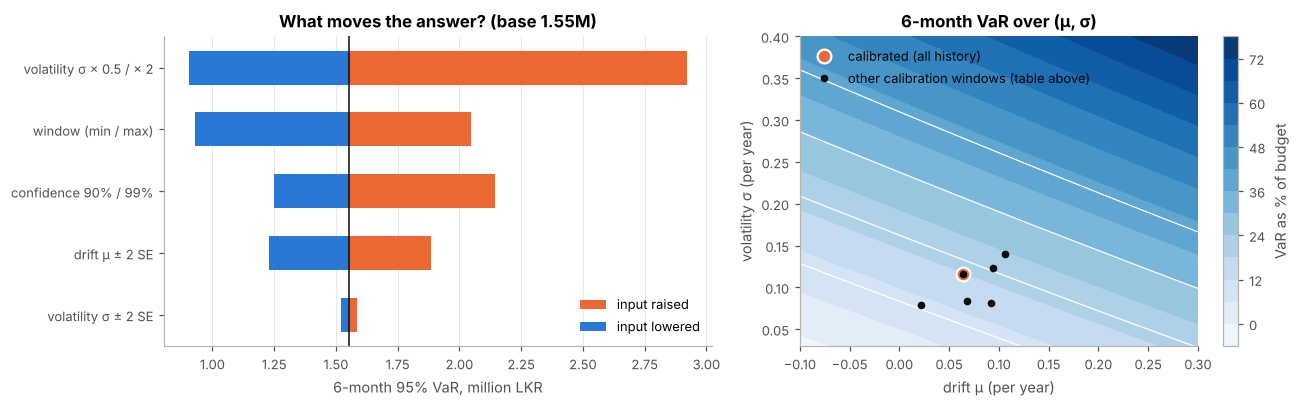

In [23]:
# (b) tornado chart for the 6-month VaR, (c) VaR surface over (mu, sigma)
T = 0.5
base = risk.analytic_var_es(S0, G.mu, G.sigma, T, AMOUNT_GBP, ALPHA)[0]
def v(mu=G.mu, sigma=G.sigma, alpha=ALPHA):
    return risk.analytic_var_es(S0, mu, sigma, T, AMOUNT_GBP, alpha)[0]
tor = pd.DataFrame({
    "drift μ ± 2 SE":        [v(mu=G.mu - 2 * G.se_mu), v(mu=G.mu + 2 * G.se_mu)],
    "volatility σ ± 2 SE":   [v(sigma=G.sigma - 2 * G.se_sigma), v(sigma=G.sigma + 2 * G.se_sigma)],
    "volatility σ × 0.5 / × 2": [v(sigma=G.sigma * 0.5), v(sigma=G.sigma * 2)],
    "confidence 90% / 99%":  [v(alpha=0.90), v(alpha=0.99)],
    "window (min / max)":    [win_tab["VaR 6m"].min(), win_tab["VaR 6m"].max()],
}, index=["low", "high"]).T
tor["range"] = tor["high"] - tor["low"]; tor = tor.sort_values("range")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.1, 1]))
ax = axes[0]
yy = np.arange(len(tor))
ax.barh(yy, (tor["high"] - base) / 1e6, left=base / 1e6, color=ORANGE, height=0.55, label="input raised")
ax.barh(yy, (tor["low"] - base) / 1e6, left=base / 1e6, color=BLUE, height=0.55, label="input lowered")
ax.axvline(base / 1e6, color=INK, lw=1)
ax.set_yticks(yy, tor.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("6-month 95% VaR, million LKR"); ax.set_title(f"What moves the answer? (base {base/1e6:.2f}M)")
ax.legend(loc="lower right")
ax = axes[1]
mus = np.linspace(-0.10, 0.30, 81); sigmas = np.linspace(0.03, 0.40, 75)
MU, SG = np.meshgrid(mus, sigmas)
Z = AMOUNT_GBP * (gbm.analytic_quantile(S0, MU, SG, T, ALPHA) - S0) / BUDGET * 100
cs = ax.contourf(MU, SG, Z, levels=14, cmap="Blues")
ax.contour(MU, SG, Z, levels=[10, 20, 30, 40], colors="white", linewidths=0.8)
ax.plot(G.mu, G.sigma, "o", color=ORANGE, mec="white", mew=1.5, ms=9, label="calibrated (all history)")
ax.plot(win_tab["mu"], win_tab["sigma"], "o", color=INK, ms=4, label="other calibration windows (table above)")
fig.colorbar(cs, ax=ax, label="VaR as % of budget")
ax.set_xlabel("drift μ (per year)"); ax.set_ylabel("volatility σ (per year)"); ax.set_title("6-month VaR over (μ, σ)")
ax.grid(False); ax.legend(loc="upper left")
fig.tight_layout(); savefig(fig, "08_sensitivity"); plt.show()

In [24]:
# (d) confidence level: GBM (exact) vs regime-switching (one large simulation)
rng = np.random.default_rng(SEED + 6)
alphas = np.array([0.90, 0.925, 0.95, 0.975, 0.99])
L_ms = risk.shortfall(regime.simulate_terminal(S0, MS, H_OBS[6], 300_000, rng), S0, AMOUNT_GBP)
conf = pd.DataFrame({
    "GBM VaR": [risk.analytic_var_es(S0, G.mu, G.sigma, 0.5, AMOUNT_GBP, a)[0] for a in alphas],
    "Regime VaR": [risk.var_es(L_ms, a)[0] for a in alphas],
    "GBM ES": [risk.analytic_var_es(S0, G.mu, G.sigma, 0.5, AMOUNT_GBP, a)[1] for a in alphas],
    "Regime ES": [risk.var_es(L_ms, a)[1] for a in alphas],
}, index=pd.Index([f"{a:.1%}" for a in alphas], name="confidence (6 months)"))
conf.style.format("{:,.0f}")

,GBM VaR,Regime VaR,GBM ES,Regime ES
confidence (6 months),,,,
90.0%,"1,250,105","1,246,331","1,651,687","1,789,862"
92.5%,"1,380,391","1,406,315","1,764,657","1,945,904"
95.0%,"1,552,271","1,625,694","1,916,201","2,165,173"
97.5%,"1,821,767","2,001,073","2,158,609","2,537,236"
99.0%,"2,144,025","2,495,030","2,454,556","3,029,127"


### 6.5 Vectorisation speed-up

The same Euler–Maruyama simulation (6-month horizon, daily steps) written three ways:
1. **pure Python** double loop over paths and days;
2. **vectorised over paths**: a Python loop over days only, NumPy across all paths (the form used in `gbm.euler_maruyama`);
3. **fully vectorised**: one `(paths × days)` array of normals and a single `np.prod`;

plus the **exact GBM terminal sampler** (no time steps), which is what the headline results use.

,µs per path,paths timed,speed-up vs loops,time for 1M paths (s)
pure Python loops,43.36,"2,000",1x,43.36
vectorised over paths,1.76,"50,000",25x,1.76
fully vectorised (np.prod),1.71,"50,000",25x,1.71
exact terminal sampler,0.01,"1,000,000","2,968x",0.01


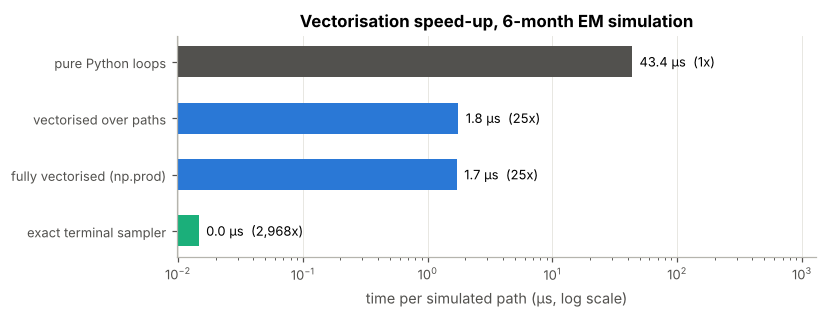

In [25]:
rng = np.random.default_rng(SEED + 7)
T, n_steps = 0.5, H_OBS[6]
def timeit(fn, n_paths, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(n_paths); best = min(best, time.perf_counter() - t0)
    return best / n_paths * 1e6      # microseconds per path

impl = {
    "pure Python loops": (lambda n: gbm.euler_maruyama_loop(S0, G.mu, G.sigma, T, n_steps, n, rng), 2_000),
    "vectorised over paths": (lambda n: gbm.euler_maruyama(S0, G.mu, G.sigma, T, gbm.brownian_increments(T, n_steps, n, rng)), 50_000),
    "fully vectorised (np.prod)": (lambda n: gbm.euler_maruyama_vectorised(S0, G.mu, G.sigma, T, n_steps, n, rng), 50_000),
    "exact terminal sampler": (lambda n: gbm.sample_terminal(S0, G.mu, G.sigma, T, n, rng), 1_000_000),
}
speed = pd.DataFrame({k: {"µs per path": timeit(f, n), "paths timed": n} for k, (f, n) in impl.items()}).T
speed["speed-up vs loops"] = speed["µs per path"].iloc[0] / speed["µs per path"]
speed["time for 1M paths (s)"] = speed["µs per path"]
display(speed.style.format({"µs per path": "{:,.2f}", "paths timed": "{:,.0f}", "speed-up vs loops": "{:,.0f}x",
                            "time for 1M paths (s)": "{:,.2f}"}))

fig, ax = plt.subplots(figsize=(7.5, 2.6))
yy = np.arange(len(speed))[::-1]
ax.barh(yy, speed["µs per path"], color=[INK2, BLUE, BLUE, AQUA], height=0.55)
for y, (k, row) in zip(yy, speed.iterrows()):
    ax.text(row["µs per path"] * 1.15, y, f"{row['µs per path']:,.1f} µs  ({row['speed-up vs loops']:,.0f}x)", va="center", fontsize=8.5)
ax.set_xscale("log"); ax.set_yticks(yy, speed.index); ax.grid(axis="y", visible=False)
ax.set_xlim(right=speed["µs per path"].max() * 30)
ax.set_xlabel("time per simulated path (µs, log scale)"); ax.set_title("Vectorisation speed-up, 6-month EM simulation")
savefig(fig, "09_vectorisation"); plt.show()

### 6.6 Answer to the research question

In [26]:
if SYNTHETIC:
    print("!!! These figures come from SYNTHETIC stand-in data and are NOT real results. !!!\n")
print(f"Planning date {PLAN_DATE:%d %b %Y}: GBP/LKR = {S0:,.2f}; budget for GBP {AMOUNT_GBP:,} at today's rate = LKR {BUDGET:,.0f}.\n")
print("Extra rupees to set aside today for 95% confidence of covering the payment:")
for m in HORIZON_MONTHS:
    g, s = gbm_mc[m]["out"], ms_mc[m]
    print(f"  {m:>2} months:  GBM  LKR {g['VaR'].mean:>10,.0f} ({g['VaR'].mean/BUDGET:5.1%} of budget, ES {g['ES'].mean:>10,.0f})"
          f"   |   regime-switching  LKR {s['VaR'].mean:>10,.0f} ({s['VaR'].mean/BUDGET:5.1%}, ES {s['ES'].mean:>10,.0f})")
print("\nBacktest breach rates (target 5%):")
print(summ["breach_rate"].unstack(0)[[f"{m}m" for m in HORIZON_MONTHS]].map(lambda x: f"{x:.1%}").to_string())

Planning date 20 Nov 2026: GBP/LKR = 435.56; budget for GBP 20,000 at today's rate = LKR 8,711,276.

Extra rupees to set aside today for 95% confidence of covering the payment:
   3 months:  GBM  LKR  1,012,972 (11.6% of budget, ES  1,254,211)   |   regime-switching  LKR  1,046,446 (12.0%, ES  1,453,497)
   6 months:  GBM  LKR  1,552,964 (17.8% of budget, ES  1,918,326)   |   regime-switching  LKR  1,624,835 (18.7%, ES  2,159,670)
  12 months:  GBM  LKR  2,461,894 (28.3% of budget, ES  3,027,589)   |   regime-switching  LKR  2,562,265 (29.4%, ES  3,318,731)

Backtest breach rates (target 5%):
                      3m     6m    12m
model                                 
No reserve         57.9%  59.5%  72.6%
GBM (all history)   6.0%   8.4%  14.5%
GBM (last year)     7.5%  10.7%  17.7%
Regime-switching    6.0%   8.4%  14.5%


## 7. Discussion and limitations

### Discussion

*Figures below are from the run on CBSL data to 20 November 2026 (S₀ = 435.56 LKR/GBP; budget LKR 8.71 million).
All simulations are seeded, so re-running the notebook on the same data reproduces them.*

**1. The answer.** Under GBM a family paying GBP 20,000 should set aside an extra **LKR 1.01 million (3 months),
LKR 1.55 million (6 months) or LKR 2.46 million (12 months)**, i.e. about **12%, 18% and 28%** on top of the budget at
today's rate, to be 95% confident of covering the payment. The regime-switching model asks for slightly more:
LKR 1.05M, 1.62M and 2.56M. The reserve grows faster than linearly in the horizon's square root because the
calibrated drift (+6.4% a year, i.e. a rupee that tends to weaken) adds to the volatility term: of the 12-month
reserve, roughly LKR 0.6 million comes from the drift alone (with zero drift in the log-rate it would be LKR 1.84M).

**2. Bad cases are worse than the reserve.** Expected Shortfall is about 24% above VaR under GBM (LKR 1.25M, 1.92M,
3.03M) and more under the regime model (LKR 1.45M, 2.16M, 3.32M: 10–16% above GBM's ES). So when the 5% bad case does
happen, the regime model expects a deeper hole than GBM does.

**3. GBM's assumptions fail, but mostly in the far tail.** Daily log-returns have excess kurtosis of about 41 and a
Student-t fit with only ν ≈ 2.2 degrees of freedom beats the Normal by over 1,200 AIC points. The regime model improves
the likelihood by about 700 log-likelihood units (AIC better by about 1,390). It finds a calm regime (σ ≈ 7.8% a year) and a
crisis regime (σ ≈ 30% a year, strong depreciation drift) that is entered rarely (8.8% of days) and is short-lived
(about 6 days on average), essentially capturing jump days such as 9–11 March 2022. Because the planning date is calm
(P(crisis) = 0.008), the two models agree at 95%. They part company further out: at 99% the regime VaR is LKR 2.50M
against GBM's 2.14M (+16%), and if a crisis were under way today the 3-month reserve would rise to LKR 1.34M (+28%).

**4. Backtest: adequate for 3 months, too small for longer horizons.** With monthly planning dates from 2015, the
all-history GBM and the regime model breached on **6.0%** of 3-month plans (Kupiec p = 0.60, consistent with 5%),
**8.4%** of 6-month plans (p = 0.10) and **14.5%** of 12-month plans (p < 0.001, under-coverage). Budgeting at today's rate
with no reserve would have left the family short on 58–73% of occasions. Calibrating on only the last year *raised*
the average reserve but did *not* reduce breaches (7.5%, 10.7%, 17.7%): it over-reserved after the crisis and
under-reserved before it. The two all-history models produced identical breach counts because, as in point 3, their 95%
reserves differ only slightly when the chain is in the calm regime.

**5. 2022: no rule calibrated on the past would have protected the family.** For 6-month plans whose payment fell
due in 2022, every model rule breached on 6 of 12 occasions (12-month: 9 of 12). The worst uncovered shortfall was
up to about LKR 2.9 million on a GBP 20,000 payment (versus 3.7 million with no reserve). The reserve helped, but the
March 2022 float, a policy decision that moved the rate about 65% in six weeks, lay far outside anything in the
2013–2021 data. The stretch goal therefore answers its own question in the negative: the two-regime model fitted on
pre-2022 data was no better than GBM at protecting a family in 2022.

**6. What matters most for the answer.** The tornado chart shows the reserve is most sensitive to the volatility
regime (halving or doubling σ moves the 6-month VaR from LKR 0.91M to 2.92M) and to the calibration window
(LKR 0.93M with the last 3 years, 2.05M with the last 5 years, which include 2022). Drift uncertainty matters too
(±2 standard errors gives LKR 1.23M–1.88M at 6 months and 1.77M–3.19M at 12 months), whereas sampling error in σ is
negligible. The Monte Carlo error itself is tiny by comparison (CI half-width about 0.1% of the estimate).

**7. Verification and numerics.** Every Monte Carlo VaR/ES lies within 0.12% of its closed-form value (|z| < 1.8);
the quantile estimator's RMSE falls like N^−0.49; Euler–Maruyama shows strong order 0.50 and weak order 1.00 and
Milstein strong order 0.99, all matching theory; the Hamilton filter matches `statsmodels` to the third decimal; and
simulated regime frequencies (0.913 / 0.087) match the stationary distribution (0.912 / 0.088). Vectorising across
paths made the simulation roughly 25–30 times faster than pure Python loops, and the exact GBM sampler roughly 3,000 times faster or more (timings vary between runs).

**Practical reading.** For a payment 3 months away, a reserve of about 12% of the rupee budget is well supported by
both the model and its backtest. For 6–12 months the model figures (18% and 28%) should be treated as a *minimum*:
the backtest shows they are breached two to three times more often than intended. Paying or converting earlier, or
using a forward contract or a foreign-currency account, removes the risk rather than reserving against it.

### Limitations
* **Indicative rate, not the family's rate.** Banks' telegraphic-transfer selling rates include a spread above the CBSL indicative rate; the reserve should be increased by that spread.
* **Model risk.** GBM's constant volatility and normal tails understate crisis risk; the two-regime model is better but still assumes normal returns within each regime and only two regimes. A 2022-scale devaluation, driven by a policy decision to float the rupee, is close to a structural break, which no model calibrated on calmer history can be expected to predict.
* **Drift uncertainty.** The drift's standard error is large, so long-horizon reserves depend heavily on it.
* **Interest ignored.** Rupees set aside today would earn deposit interest (and GBP could be bought forward or held in a foreign-currency account); both reduce the effective cost of the reserve and are natural extensions.
* **Overlapping backtest windows** make the breach indicators dependent, so the Kupiec test is indicative only.

## 8. References
* Central Bank of Sri Lanka, *Exchange Rates*. <https://www.cbsl.gov.lk/rates-and-indicators/exchange-rates>
* Frankfurter API, *Central Bank of Sri Lanka provider*. <https://frankfurter.dev/providers/cbsl/>
* Bournemouth University, *International tuition fees 2026/27*. <https://www.bournemouth.ac.uk/node/33346>
* Glasserman, P. (2003). *Monte Carlo Methods in Financial Engineering*. Springer.
* Kloeden, P. E. & Platen, E. (1992). *Numerical Solution of Stochastic Differential Equations*. Springer.
* Higham, D. J. (2001). An algorithmic introduction to numerical simulation of stochastic differential equations. *SIAM Review*, 43(3), 525–546.
* Hamilton, J. D. (1989). A new approach to the economic analysis of nonstationary time series and the business cycle. *Econometrica*, 57(2), 357–384.
* Kim, C.-J. (1994). Dynamic linear models with Markov-switching. *Journal of Econometrics*, 60(1–2), 1–22.
* Kupiec, P. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
* Law, A. M. (2015). *Simulation Modeling and Analysis* (5th ed.). McGraw-Hill.